In [1]:
## Run from scvi environment
## Need specific scanpy versions to be able to properly read cellbender formats

In [3]:
import os
import sys
import math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scanpy as sc
import anndata as ad
import muon as mu
from muon import MuData

import scvi
import session_info

sys.path.append('/nfs/casm/team215mg/users/od5/scripts/')
from single_cell_utils import *

In [4]:
session_info.show()

/software/conda/users/od5/scvi_24/lib/python3.9/site-packages/session_info/main.py:213: UserWarning: The '__version__' attribute is deprecated and will be removed in MarkupSafe 3.1. Use feature detection, or `importlib.metadata.version("markupsafe")`, instead.
  mod_version = _find_version(mod.__version__)


In [6]:
work_dir = '/lustre/scratch125/casm/teams/team215/users/od5/projects/celltherapy/ipsc/multiome/gex_adata/tf_pilot/batch1/ipsc/'
os.makedirs(work_dir , exist_ok=True)

In [25]:
## Read metadata table (library level)
sample_metad = pd.read_csv('/nfs/casm/team215mg/users/od5/projects/celltherapy/ipsc/multiome/tf_pilot/001_preprocessing/immnk_by_sample_manifest_updated - immnk_20251028.csv')

In [10]:
## Read TF barcodes
barcodes1 = pd.read_csv('/lustre/scratch125/casm/teams/team215/users/od5/projects/celltherapy/ipsc/multiome/tf_barcodes/Imm_NK15385635.csv', index_col=0)
barcodes1['sample_barcode'] = 'multi_Imm_NK15385635-' + barcodes1.index

In [11]:
## Concatenate barcodes 
# barcodes = pd.concat([barcodes1, barcodes2, barcodes3])
barcodes = barcodes1

In [26]:
# Subset to TF pilot samples
sample_metad = sample_metad.iloc[3:4]

In [27]:
sample_metad.reset_index(inplace=True, drop=True)

In [28]:
sample_metad.head()

,run_ID,run_date,enrichment,sort_type,sample_type,study,sample_ID,sample_GEX,sample_GEX_2,sample_ATAC,...,cell_calling_mode,markerGenes,souporcell_run_ID,souporcell_K,souporcell_dir,cellbender_dir,n_cells_targeted,n_cells_cellranger,sample_description,comments
0,run_004,9/12/2024,total,NaN,kolf2_ipsc,ImmNK,multi_Imm_NK15385635,Imm_NK15385635,NaN,Imm_NK15385851,...,union,/nfs/casm/team215mg/users/od5/projects/cellthe...,run_004,1,NaN,/lustre/scratch125/casm/teams/team215/users/od...,16000,7000,iPSC_batch2,NaN


In [29]:
## Initialise the full adata object
X = pd.DataFrame(np.empty((0,0)))
obs = pd.DataFrame(index=X.index)
var = pd.DataFrame(index=X.columns) 
X = X.values

adata_full = ad.AnnData(X=X, obs=obs, var=var)

## For each sample:
for i in range(sample_metad.shape[0]):
    sample_ID = sample_metad['sample_ID'][i]
    print(sample_ID)
    ## Read the barcodes that passed QC (first round) from multiQC
    barcode_stats = pd.read_csv((sample_metad['multiQC_dir'][i] + '/multiQC_barcode_info.tsv'), index_col=0)
    barcode_stats['sample_barcode'] = barcode_stats.index.tolist().copy()
    ## Keep a subset of the metadata
    barcode_stats = barcode_stats[['sample_barcode', 'barcode', 'gex_barcode', 'atac_barcode', 'gex_umis_count',
                                      'gex_genes_count',  'snap_atac_fragments', 'snap_TSS_enrichment', 'f_intronic', 'is_cell', 
                                      'EDM_is_cell', 'multiQC_leiden',  'multiQC_is_cell', 'atac_doublet_score']]
    ## Update some of the metadata columns
    barcode_stats = barcode_stats.rename(columns = {'gex_umis_count': 'cellranger_gex_umis_count', 'gex_genes_count': 'cellranger_gex_genes_count',
                                    'is_cell': 'cellranger_is_cell'})
    
    ## Add sample ID to barcode stats
    barcode_stats['sample_ID'] = sample_ID
    
    ## For the multiQC leiden clustering, add the sample_ID to not mix them up across samples
    barcode_stats['multiQC_leiden'] = barcode_stats['sample_ID'] + '_' + barcode_stats['multiQC_leiden'].astype(str)
    
    
    ## Read cellbendered matrix (raw)
    adata = sc.read_10x_h5((sample_metad['cellbender_dir'][i] + '/cellbender_FPR_0.05.h5'))
    adata.var_names_make_unique()
    
    ## And subset for cells that passed QC
    adata = adata[barcode_stats['gex_barcode']]
    
    ## Add all cell info
    adata.obs = barcode_stats.copy()
    
    ## Calculate QC metrics
    adata = calculate_qc_metrics(adata)
    
    # Repeat doublet detection with cellbendered counts
    sc.external.pp.scrublet(adata)

    # Incorporate AMULET scores
    amulet = pd.read_csv((sample_metad['multiQC_dir'][i] + '/amulet/MultipletProbabilities.txt'), sep='\t')
    amulet['sample_barcode'] = sample_ID + '-' + amulet['barcode'] 
    amulet = amulet[['sample_barcode', 'p-value',	'q-value']].rename(columns={'p-value': 'amulet_pval', 'q-value': 'amulet_qval'})
    amulet.index = amulet['sample_barcode'].tolist()
    adata.obs = pd.merge(adata.obs, amulet[['amulet_pval', 'amulet_qval']], left_index=True, right_index=True, how='left')
    
    adata_full = ad.concat([adata_full,adata],join='outer')
    
    print(adata_full)

/software/conda/users/od5/scvi_24/lib/python3.9/site-packages/anndata/_core/aligned_df.py:67: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/software/conda/users/od5/scvi_24/lib/python3.9/site-packages/anndata/_core/aligned_df.py:67: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


multi_Imm_NK15385635


/software/conda/users/od5/scvi_24/lib/python3.9/site-packages/anndata/_core/anndata.py:1820: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/software/conda/users/od5/scvi_24/lib/python3.9/site-packages/anndata/_core/anndata.py:1820: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/software/conda/users/od5/scvi_24/lib/python3.9/site-packages/sklearn/utils/deprecation.py:87: FutureWarning: Function scrublet is deprecated; Import from sc.pp instead
  warnings.warn(msg, category=FutureWarning)
/software/conda/users/od5/scvi_24/lib/python3.9/site-packages/scanpy/preprocessing/_normalization.py:233: UserWarning: Some cells have zero counts
  warn(UserWarning("Some cells have zero counts"))


AnnData object with n_obs × n_vars = 21983 × 36601
    obs: 'sample_barcode', 'barcode', 'gex_barcode', 'atac_barcode', 'cellranger_gex_umis_count', 'cellranger_gex_genes_count', 'snap_atac_fragments', 'snap_TSS_enrichment', 'f_intronic', 'cellranger_is_cell', 'EDM_is_cell', 'multiQC_leiden', 'multiQC_is_cell', 'atac_doublet_score', 'sample_ID', 'n_genes_by_counts', 'total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb', 'doublet_score', 'predicted_doublet', 'amulet_pval', 'amulet_qval'


In [30]:
adata_full

AnnData object with n_obs × n_vars = 21983 × 36601
    obs: 'sample_barcode', 'barcode', 'gex_barcode', 'atac_barcode', 'cellranger_gex_umis_count', 'cellranger_gex_genes_count', 'snap_atac_fragments', 'snap_TSS_enrichment', 'f_intronic', 'cellranger_is_cell', 'EDM_is_cell', 'multiQC_leiden', 'multiQC_is_cell', 'atac_doublet_score', 'sample_ID', 'n_genes_by_counts', 'total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb', 'doublet_score', 'predicted_doublet', 'amulet_pval', 'amulet_qval'

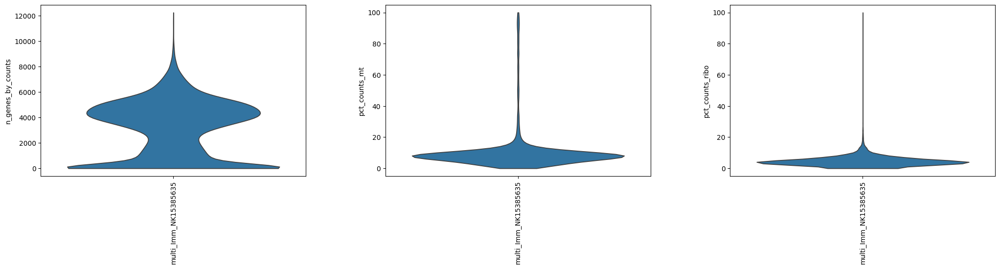

In [31]:
## Examine distributions for basic QC across samples
sc.pl.violin(adata_full, groupby='sample_ID', keys = ['n_genes_by_counts', 'pct_counts_mt', 'pct_counts_ribo'], rotation=90, size=0)

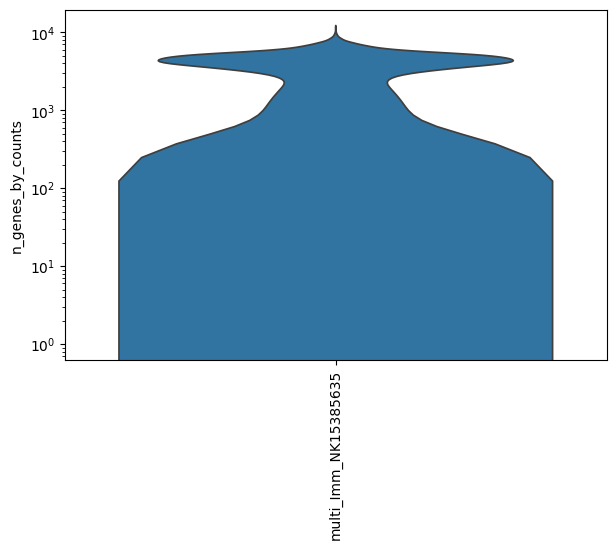

In [32]:
sc.pl.violin(adata_full, groupby='sample_ID', keys = ['n_genes_by_counts'], log=True, rotation=90, size=0)

In [33]:
## Filter for 400 genes, up to 30% mitochondrial reads and up to 15% ribosomal reads
adata_full = adata_full[(adata_full.obs['n_genes_by_counts']>= 400) & \
(adata_full.obs['pct_counts_mt'] < 30) & (adata_full.obs['pct_counts_ribo'] < 15)]

In [34]:
adata_full

View of AnnData object with n_obs × n_vars = 17276 × 36601
    obs: 'sample_barcode', 'barcode', 'gex_barcode', 'atac_barcode', 'cellranger_gex_umis_count', 'cellranger_gex_genes_count', 'snap_atac_fragments', 'snap_TSS_enrichment', 'f_intronic', 'cellranger_is_cell', 'EDM_is_cell', 'multiQC_leiden', 'multiQC_is_cell', 'atac_doublet_score', 'sample_ID', 'n_genes_by_counts', 'total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb', 'doublet_score', 'predicted_doublet', 'amulet_pval', 'amulet_qval'
    uns: 'sample_ID_colors'

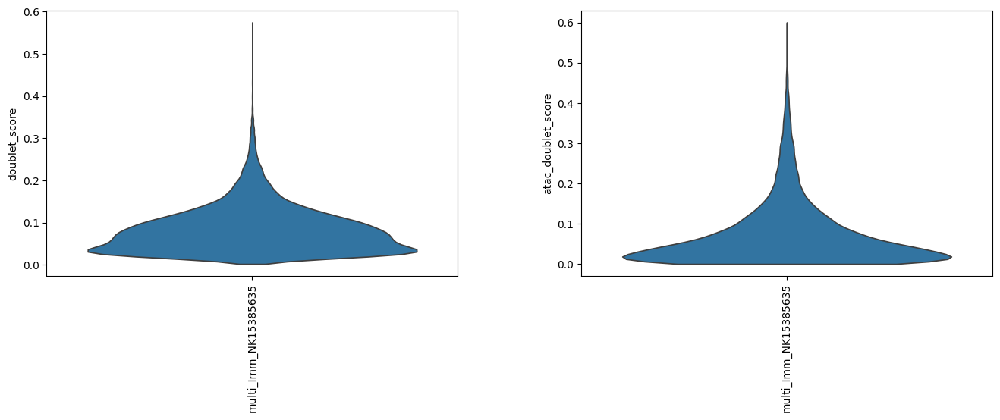

In [35]:
sc.pl.violin(adata_full, groupby='sample_ID', keys = ['doublet_score', 'atac_doublet_score'], rotation=90, size=0)

In [36]:
## Agreement between GEX and ATAC doublet score?
from scipy.stats import pearsonr

pearsonr(adata_full.obs['doublet_score'], adata_full.obs['atac_doublet_score'])

PearsonRResult(statistic=0.25769035499152765, pvalue=4.3016462103414455e-260)

In [37]:
## Incorporate sample-level metadata
x = pd.merge(adata_full.obs, sample_metad[['sample_ID', 'enrichment', 'sample_description']],
             on='sample_ID', how='left')
x.index = adata_full.obs.index.copy()
adata_full.obs = x.copy()

In [38]:
## Convert boolean to make compatible with adata conventions
adata_full.obs['predicted_doublet'] = adata_full.obs['predicted_doublet'].astype(int)

In [39]:
## Preserve counts
adata_full.layers["counts"] = adata_full.X.copy() 

In [40]:
## Incorporate TF barcodes
x = pd.merge(adata_full.obs, barcodes, on='sample_barcode', how='left')
x.index = adata_full.obs.index.copy()
adata_full.obs = x.copy()

In [41]:
## Export
adata_full.write_h5ad((work_dir + 'adata_prefilter.h5ad'))

In [42]:
## Find neighbors, run Leiden clustering and UMAP

# Normalizing to median total counts
sc.pp.normalize_total(adata_full)
# Logarithmize the data
sc.pp.log1p(adata_full)

sc.pp.highly_variable_genes(adata_full)
sc.pp.pca(adata_full)
sc.pp.neighbors(adata_full)
sc.tl.leiden(adata_full)
sc.tl.umap(adata_full)

/tmp/ipykernel_4044189/727253141.py:11: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(adata_full)


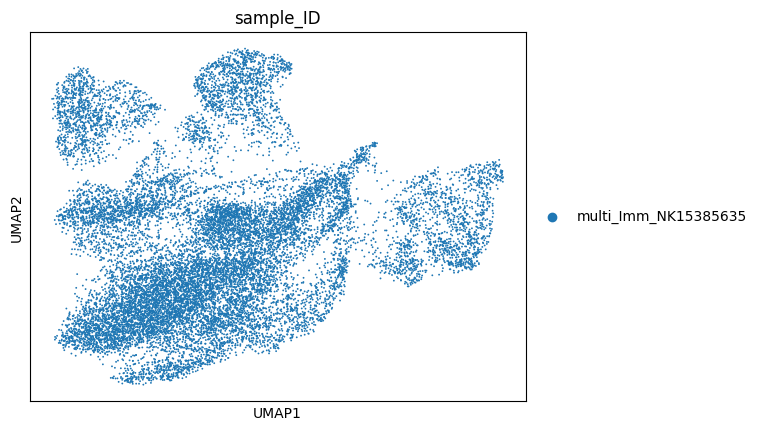

In [43]:
sc.pl.umap(adata_full, color=['sample_ID'])

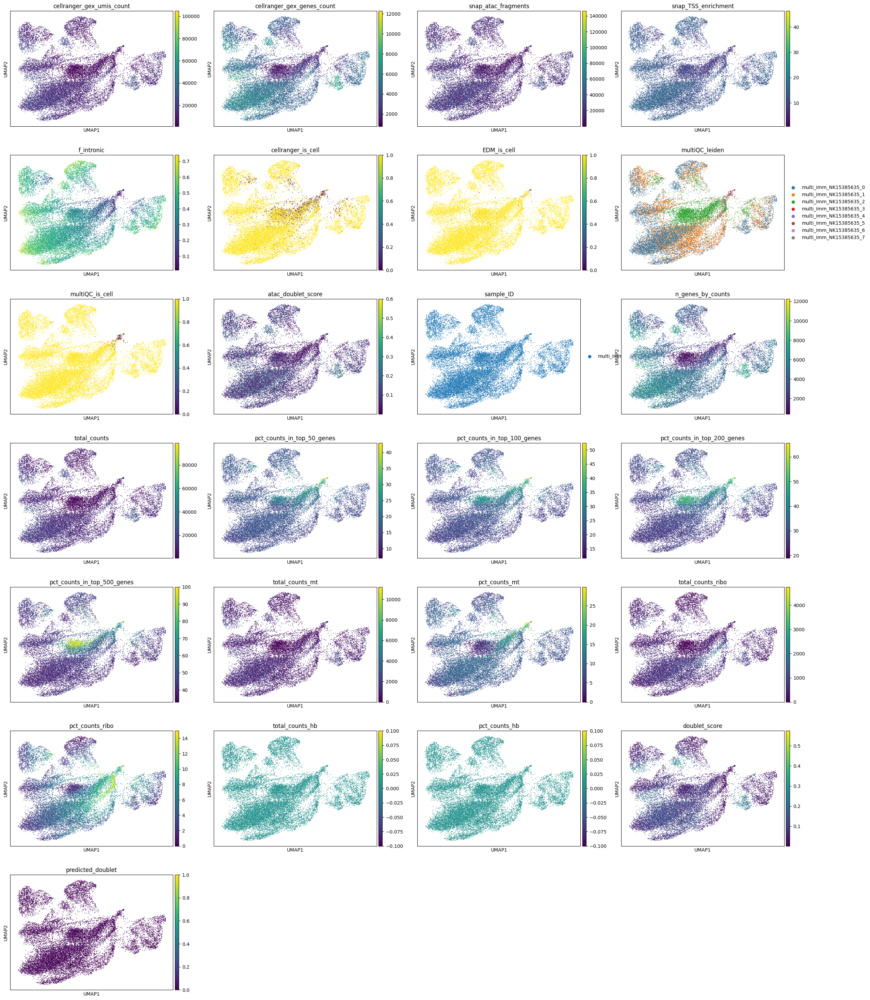

In [44]:
sc.pl.umap(adata_full, color=['cellranger_gex_umis_count', 'cellranger_gex_genes_count', 'snap_atac_fragments', 'snap_TSS_enrichment', 'f_intronic',
                              'cellranger_is_cell', 'EDM_is_cell', 'multiQC_leiden', 'multiQC_is_cell', 'atac_doublet_score', 'sample_ID',
                              'n_genes_by_counts', 'total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes',
                              'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb',
                              'doublet_score', 'predicted_doublet'])

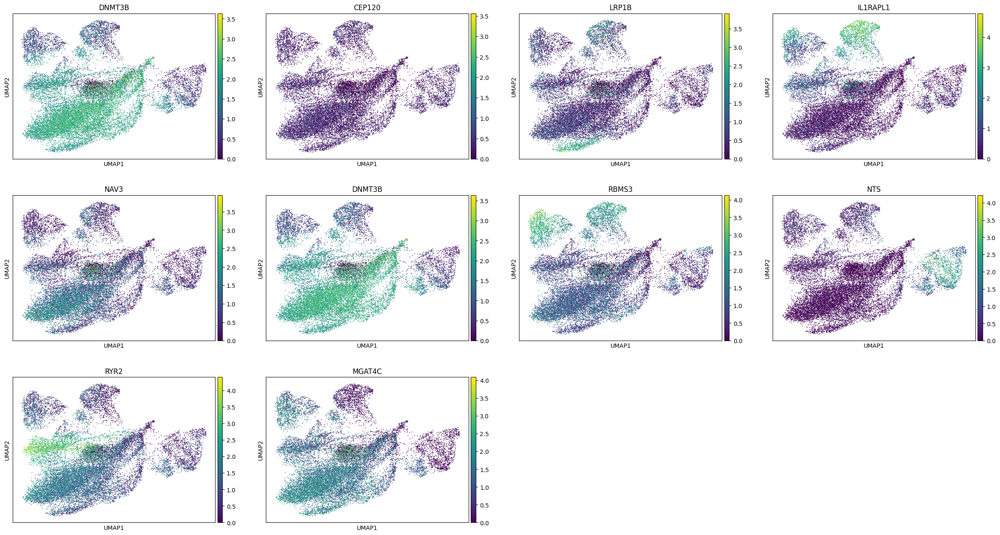

In [45]:
sc.pl.umap(adata_full, color=['DNMT3B', 'CEP120', 'LRP1B', 'IL1RAPL1', 'NAV3', 'DNMT3B', 'RBMS3', 'NTS', 'RYR2', 'MGAT4C'], legend_loc='on data')

In [46]:
adata_full

AnnData object with n_obs × n_vars = 17276 × 36601
    obs: 'sample_barcode', 'barcode', 'gex_barcode', 'atac_barcode', 'cellranger_gex_umis_count', 'cellranger_gex_genes_count', 'snap_atac_fragments', 'snap_TSS_enrichment', 'f_intronic', 'cellranger_is_cell', 'EDM_is_cell', 'multiQC_leiden', 'multiQC_is_cell', 'atac_doublet_score', 'sample_ID', 'n_genes_by_counts', 'total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb', 'doublet_score', 'predicted_doublet', 'amulet_pval', 'amulet_qval', 'enrichment', 'sample_description', 'Control_pos2', 'CEBPA_pos2', 'CEBPD_pos2', 'EBF1_pos2', 'FOXO3_pos2', 'HOPX_pos2', 'PRDM1_pos2', 'RUNX2_pos2', 'TBX21_pos2', 'TCF7_pos2', 'max', 'perturbation', 'leiden'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'sample_ID_colors', 'log1

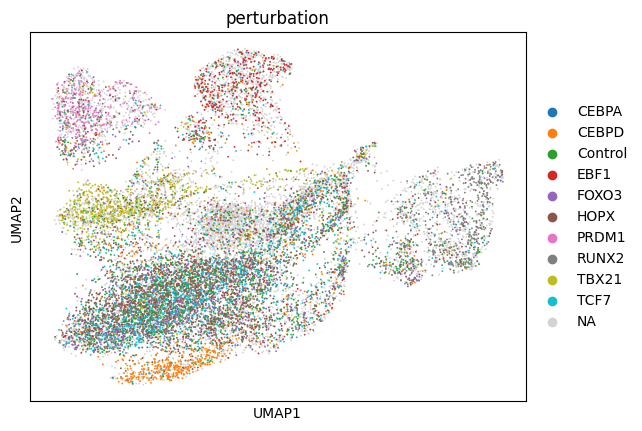

In [47]:
sc.pl.umap(adata_full, color=['perturbation'])

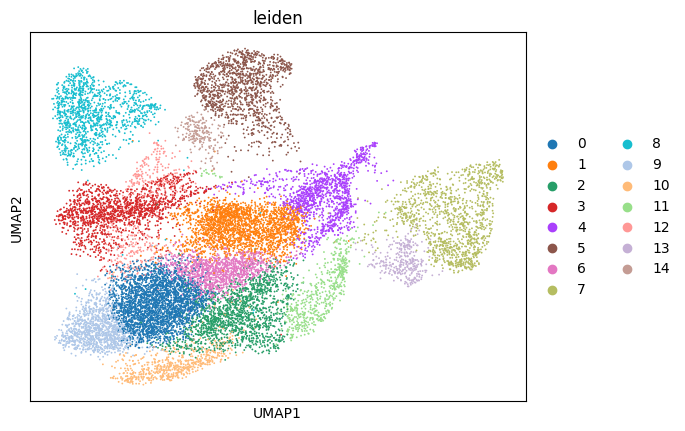

In [48]:
sc.pl.umap(adata_full, color=['leiden'])